# Formulaciones del problema y modelos baseline

Este notebook convierte los hallazgos del EDA en preguntas predictivas explícitas. La distinción importa: cambiar la etiqueta, el horizonte o la población en riesgo produce problemas distintos, aunque todos usen las mismas columnas.

**Objetivo de competencia:** ordenar a los clientes activos en diciembre según la probabilidad de que su primera conversión ocurra ese mes. La métrica principal es Gini (`2 × AUC - 1`).

| Formulación | Unidad / etiqueta | Uso | ¿Alineada con diciembre? |
|---|---|---|---|
| F0. Clasificación i.i.d. | fila cliente–mes, split aleatorio | control negativo para medir optimismo | No |
| F1. Hazard de perfil | fila activa; convierte este mes | baseline válido con atributos actuales | Sí |
| F2. Hazard con historia | F1 + exposición/cohorte/cambios disponibles | explota estructura longitudinal | Sí |
| F3. Hazard segmentado | modelos separados para primera observación y recurrentes | permite mecanismos distintos | Sí |
| F4. Conversión a 3 meses desde alta | un cliente al entrar; evento en 0–2 meses | priorización de adquisición | No; responde otra pregunta |

La comparación principal usa **enero–octubre para entrenar y noviembre para validar**, simulando el salto noviembre → diciembre. F4 se evalúa en la cohorte de septiembre, cuyo horizonte completo termina en noviembre.

In [2]:
# Librerías, reproducibilidad y estilo.
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score, log_loss,
    brier_score_loss, roc_curve,
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (11, 5.5), "figure.dpi": 110, "axes.titleweight": "bold"})

SEED = 42
DATA_DIR = Path(".")

## 1. Panel y features disponibles al momento de decisión

In [3]:
# Se concatena test solo para construir trayectorias; nunca se usan sus etiquetas (no existen).
train_raw = pd.read_csv(DATA_DIR / "train.csv")
test_raw = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

panel = pd.concat([
    train_raw.assign(_split="train"),
    test_raw.assign(objetivo=np.nan, _split="test"),
], ignore_index=True).sort_values(["id_cliente", "mes"]).reset_index(drop=True)

grupo = panel.groupby("id_cliente", sort=False)
panel["meses_previos_observados"] = grupo.cumcount()
panel["primera_observacion"] = panel["meses_previos_observados"].eq(0).astype(int)
panel["cohorte_mes"] = grupo["mes"].transform("min")

# AAAAMM no se resta directamente: se transforma a un índice mensual lineal.
def indice_mensual(s: pd.Series) -> pd.Series:
    return (s // 100) * 12 + (s % 100)

panel["mes_ordinal"] = indice_mensual(panel["mes"])
panel["cohorte_ordinal"] = indice_mensual(panel["cohorte_mes"])

# Lags estrictamente retrospectivos dentro del cliente.
panel["interaccion_previa"] = grupo["dias_ultima_interaccion"].shift(1)
panel["delta_interaccion"] = panel["dias_ultima_interaccion"] - panel["interaccion_previa"]
panel["cambio_interaccion"] = panel["delta_interaccion"].fillna(0).ne(0).astype(int)
panel["interaccion_menos_transaccion"] = (
    panel["dias_ultima_interaccion"] - panel["dias_ultima_transaccion"]
)
panel["interaccion_previa"] = panel["interaccion_previa"].fillna(panel["dias_ultima_interaccion"])
panel["delta_interaccion"] = panel["delta_interaccion"].fillna(0)

perfil = [c for c in test_raw.columns if c not in ["id_cliente", "mes"]]
historia = perfil + [
    "meses_previos_observados", "primera_observacion", "cohorte_ordinal",
    "mes_ordinal", "interaccion_previa", "delta_interaccion",
    "cambio_interaccion", "interaccion_menos_transaccion",
]

categoricas = [
    c for c in perfil
    if panel[c].dtype == "object" or pd.api.types.is_bool_dtype(panel[c])
]
# CatBoost exige un tipo homogéneo para categorías y sklearn las codificará one-hot.
for col in categoricas:
    panel[col] = panel[col].astype(str)

desarrollo = panel.loc[panel["_split"].eq("train")].copy()
test_modelo = panel.loc[panel["_split"].eq("test")].copy()

display(pd.Series({
    "filas desarrollo": len(desarrollo),
    "variables de perfil": len(perfil),
    "variables con historia": len(historia),
    "filas test": len(test_modelo),
}, name="valor").to_frame())

,valor
filas desarrollo,110100
variables de perfil,22
variables con historia,30
filas test,9900


In [4]:
# Corte fuera de tiempo que reproduce la operación de predecir el siguiente mes.
dev_temporal = desarrollo.loc[desarrollo["mes"].le(202610)].copy()
val_temporal = desarrollo.loc[desarrollo["mes"].eq(202611)].copy()

auditoria_split = pd.Series({
    "filas train ene-oct": len(dev_temporal),
    "filas validación noviembre": len(val_temporal),
    "clientes train": dev_temporal["id_cliente"].nunique(),
    "clientes validación": val_temporal["id_cliente"].nunique(),
    "clientes compartidos": len(set(dev_temporal.id_cliente) & set(val_temporal.id_cliente)),
    "clientes nuevos en validación": int(val_temporal["primera_observacion"].sum()),
    "tasa train": dev_temporal["objetivo"].mean(),
    "tasa validación": val_temporal["objetivo"].mean(),
}, name="valor")
display(auditoria_split.to_frame())

,valor
filas train ene-oct,"100,600.0000"
filas validación noviembre,"9,500.0000"
clientes train,"23,900.0000"
clientes validación,"9,500.0000"
clientes compartidos,"8,772.0000"
clientes nuevos en validación,728.0000
tasa train,0.1504
tasa validación,0.1515


Los clientes compartidos entre train y noviembre **no son fuga** bajo un corte temporal: representan sobrevivientes observados hasta octubre y aún en riesgo en noviembre. La fuga aparece si una fila futura del mismo cliente entra en entrenamiento para predecir una fila pasada.

## 2. Métricas y familias de modelos baseline

In [5]:
# AUC/Gini miden ranking; log-loss y Brier evalúan calidad probabilística.
def metricas(y_true, prob, nombre, formulacion, muestra="noviembre", segundos=np.nan):
    auc = roc_auc_score(y_true, prob)
    return {
        "formulación": formulacion,
        "modelo": nombre,
        "muestra": muestra,
        "n": len(y_true),
        "tasa_real": np.mean(y_true),
        "prob_media": np.mean(prob),
        "AUC": auc,
        "Gini": 2 * auc - 1,
        "AP": average_precision_score(y_true, prob),
        "LogLoss": log_loss(y_true, prob),
        "Brier": brier_score_loss(y_true, prob),
        "segundos": segundos,
    }

def crear_logistica(features):
    cats = [c for c in features if c in categoricas]
    nums = [c for c in features if c not in cats]
    preproceso = ColumnTransformer([
        ("num", StandardScaler(), nums),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cats),
    ])
    return make_pipeline(preproceso, LogisticRegression(max_iter=600, C=1.0))

def crear_catboost(iterations=350):
    return CatBoostClassifier(
        iterations=iterations,
        depth=6,
        learning_rate=.05,
        loss_function="Logloss",
        eval_metric="AUC",
        l2_leaf_reg=5,
        random_seed=SEED,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1,
    )

resultados = []
predicciones_noviembre = {}
modelos = {}

Se usan tres niveles de complejidad:

- **Prior mensual:** todos reciben la tasa de conversión de entrenamiento; verifica calibración base, AUC = 0.5.
- **Regresión logística:** baseline lineal, interpretable y con one-hot para categorías.
- **CatBoost:** baseline no lineal que captura interacciones y categorías sin target encoding manual.

No se ajustan hiperparámetros contra noviembre; solo se usa *early stopping*. Así, noviembre sigue siendo una estimación razonablemente honesta del baseline.

## 3. F1 — Hazard mensual usando únicamente el perfil actual

In [6]:
# Baseline constante.
p_prior = np.repeat(dev_temporal["objetivo"].mean(), len(val_temporal))
resultados.append(metricas(
    val_temporal["objetivo"], p_prior, "Prior mensual", "F1 Hazard perfil"
))
predicciones_noviembre["Prior mensual"] = p_prior

# Regresión logística.
inicio = time.perf_counter()
log_perfil = crear_logistica(perfil)
log_perfil.fit(dev_temporal[perfil], dev_temporal["objetivo"])
p_log_perfil = log_perfil.predict_proba(val_temporal[perfil])[:, 1]
resultados.append(metricas(
    val_temporal["objetivo"], p_log_perfil, "Logística", "F1 Hazard perfil",
    segundos=time.perf_counter() - inicio,
))
predicciones_noviembre["Logística perfil"] = p_log_perfil
modelos["log_perfil"] = log_perfil

# CatBoost con early stopping en noviembre.
inicio = time.perf_counter()
cat_perfil = crear_catboost()
cat_perfil.fit(
    dev_temporal[perfil], dev_temporal["objetivo"],
    cat_features=[c for c in perfil if c in categoricas],
    eval_set=(val_temporal[perfil], val_temporal["objetivo"]),
    early_stopping_rounds=50,
    verbose=False,
)
p_cat_perfil = cat_perfil.predict_proba(val_temporal[perfil])[:, 1]
resultados.append(metricas(
    val_temporal["objetivo"], p_cat_perfil, "CatBoost", "F1 Hazard perfil",
    segundos=time.perf_counter() - inicio,
))
predicciones_noviembre["CatBoost perfil"] = p_cat_perfil
modelos["cat_perfil"] = cat_perfil

display(pd.DataFrame(resultados).query("formulación == 'F1 Hazard perfil'"))
print("Mejor iteración CatBoost:", cat_perfil.get_best_iteration())

,formulación,modelo,muestra,n,tasa_real,prob_media,AUC,Gini,AP,LogLoss,Brier,segundos
0,F1 Hazard perfil,Prior mensual,noviembre,9500,0.1515,0.1504,0.5000,0.0000,0.1515,0.4253,0.1285,NaN
1,F1 Hazard perfil,Logística,noviembre,9500,0.1515,0.1426,0.6011,0.2021,0.2102,0.4171,0.1264,0.7993
2,F1 Hazard perfil,CatBoost,noviembre,9500,0.1515,0.1389,0.6187,0.2374,0.2273,0.4107,0.1248,31.4896


Mejor iteración CatBoost: 236


## 4. F2 — Hazard mensual enriquecido con historia

In [7]:
# Las features históricas se calcularon con shift/cumcount, sin mirar objetivos futuros.
inicio = time.perf_counter()
log_historia = crear_logistica(historia)
log_historia.fit(dev_temporal[historia], dev_temporal["objetivo"])
p_log_historia = log_historia.predict_proba(val_temporal[historia])[:, 1]
resultados.append(metricas(
    val_temporal["objetivo"], p_log_historia, "Logística", "F2 Hazard + historia",
    segundos=time.perf_counter() - inicio,
))
predicciones_noviembre["Logística historia"] = p_log_historia
modelos["log_historia"] = log_historia

inicio = time.perf_counter()
cat_historia = crear_catboost()
cat_historia.fit(
    dev_temporal[historia], dev_temporal["objetivo"],
    cat_features=[c for c in historia if c in categoricas],
    eval_set=(val_temporal[historia], val_temporal["objetivo"]),
    early_stopping_rounds=50,
    verbose=False,
)
p_cat_historia = cat_historia.predict_proba(val_temporal[historia])[:, 1]
resultados.append(metricas(
    val_temporal["objetivo"], p_cat_historia, "CatBoost", "F2 Hazard + historia",
    segundos=time.perf_counter() - inicio,
))
predicciones_noviembre["CatBoost historia"] = p_cat_historia
modelos["cat_historia"] = cat_historia

display(pd.DataFrame(resultados).query("formulación == 'F2 Hazard + historia'"))
print("Mejor iteración CatBoost:", cat_historia.get_best_iteration())

,formulación,modelo,muestra,n,tasa_real,prob_media,AUC,Gini,AP,LogLoss,Brier,segundos
3,F2 Hazard + historia,Logística,noviembre,9500,0.1515,0.1496,0.6007,0.2015,0.2115,0.4168,0.1263,0.9890
4,F2 Hazard + historia,CatBoost,noviembre,9500,0.1515,0.1467,0.6190,0.2381,0.2267,0.4102,0.1247,27.4723


Mejor iteración CatBoost: 164


## 5. F3 — Hazard segmentado: primera observación vs recurrentes

In [8]:
# Se entrenan dos CatBoost. La segmentación reduce tamaño y puede aumentar varianza.
p_segmentado = np.zeros(len(val_temporal))
detalle_segmentos = []
inicio_total = time.perf_counter()

for primera, nombre in [(1, "primera observación"), (0, "recurrente")]:
    mask_dev = dev_temporal["primera_observacion"].eq(primera)
    mask_val = val_temporal["primera_observacion"].eq(primera)
    modelo = crear_catboost()
    modelo.fit(
        dev_temporal.loc[mask_dev, historia], dev_temporal.loc[mask_dev, "objetivo"],
        cat_features=[c for c in historia if c in categoricas],
        eval_set=(val_temporal.loc[mask_val, historia], val_temporal.loc[mask_val, "objetivo"]),
        early_stopping_rounds=50,
        verbose=False,
    )
    prob = modelo.predict_proba(val_temporal.loc[mask_val, historia])[:, 1]
    p_segmentado[mask_val.to_numpy()] = prob
    detalle_segmentos.append(metricas(
        val_temporal.loc[mask_val, "objetivo"], prob,
        f"CatBoost {nombre}", "F3 Hazard segmentado", muestra=nombre,
    ))
    modelos[f"cat_segmento_{primera}"] = modelo

resultados.append(metricas(
    val_temporal["objetivo"], p_segmentado, "CatBoost segmentado",
    "F3 Hazard segmentado", segundos=time.perf_counter() - inicio_total,
))
predicciones_noviembre["CatBoost segmentado"] = p_segmentado
display(pd.DataFrame(detalle_segmentos + [resultados[-1]]))

,formulación,modelo,muestra,n,tasa_real,prob_media,AUC,Gini,AP,LogLoss,Brier,segundos
0,F3 Hazard segmentado,CatBoost primera observación,primera observación,728,0.1964,0.1751,0.5924,0.1848,0.2683,0.4898,0.1557,NaN
1,F3 Hazard segmentado,CatBoost recurrente,recurrente,8772,0.1477,0.1444,0.6173,0.2345,0.2209,0.4046,0.1223,NaN
2,F3 Hazard segmentado,CatBoost segmentado,noviembre,9500,0.1515,0.1468,0.6172,0.2344,0.2258,0.4111,0.1249,41.2211


## 6. Comparación justa de formulaciones mensuales

,formulación,modelo,muestra,n,tasa_real,prob_media,AUC,Gini,AP,LogLoss,Brier,segundos
0,F2 Hazard + historia,CatBoost,noviembre,9500,0.1515,0.1467,0.6190,0.2381,0.2267,0.4102,0.1247,27.4723
1,F1 Hazard perfil,CatBoost,noviembre,9500,0.1515,0.1389,0.6187,0.2374,0.2273,0.4107,0.1248,31.4896
2,F3 Hazard segmentado,CatBoost segmentado,noviembre,9500,0.1515,0.1468,0.6172,0.2344,0.2258,0.4111,0.1249,41.2211
3,F1 Hazard perfil,Logística,noviembre,9500,0.1515,0.1426,0.6011,0.2021,0.2102,0.4171,0.1264,0.7993
4,F2 Hazard + historia,Logística,noviembre,9500,0.1515,0.1496,0.6007,0.2015,0.2115,0.4168,0.1263,0.9890
5,F1 Hazard perfil,Prior mensual,noviembre,9500,0.1515,0.1504,0.5000,0.0000,0.1515,0.4253,0.1285,NaN


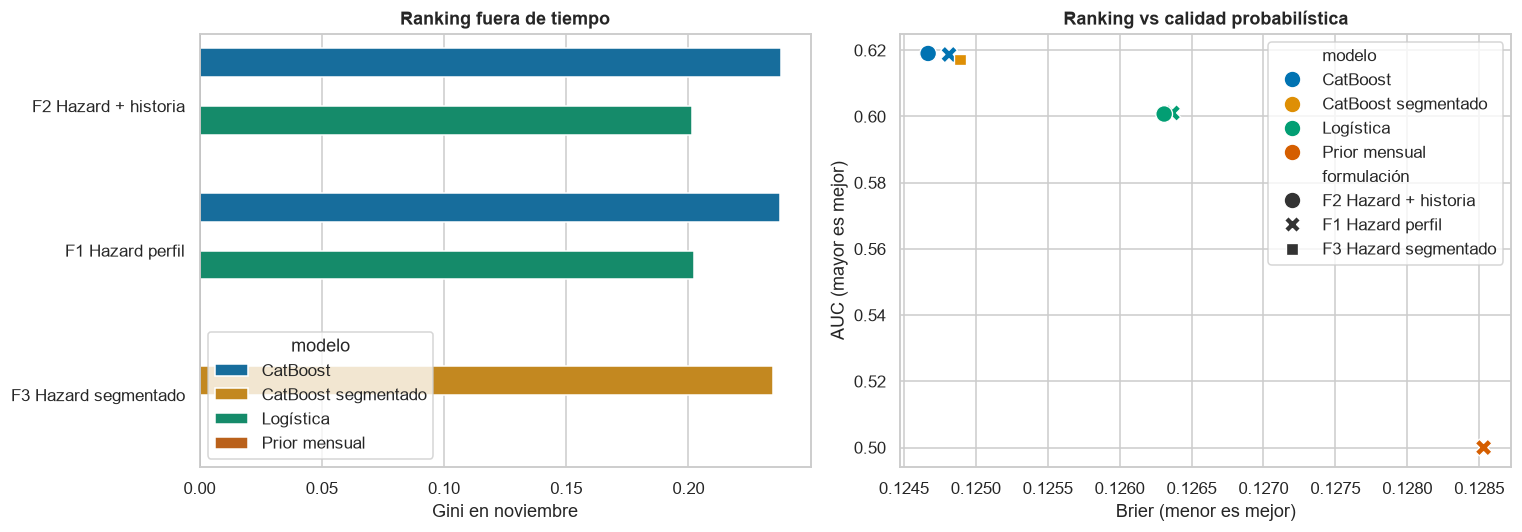

In [9]:
tabla_mensual = (
    pd.DataFrame(resultados)
    .query("muestra == 'noviembre'")
    .sort_values(["AUC", "LogLoss"], ascending=[False, True])
    .reset_index(drop=True)
)
display(tabla_mensual)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=tabla_mensual, y="formulación", x="Gini", hue="modelo", ax=axes[0])
axes[0].set(title="Ranking fuera de tiempo", xlabel="Gini en noviembre", ylabel="")
axes[0].axvline(0, color="black", lw=1)

sns.scatterplot(data=tabla_mensual, x="Brier", y="AUC", hue="modelo", style="formulación", s=120, ax=axes[1])
axes[1].set(title="Ranking vs calidad probabilística", xlabel="Brier (menor es mejor)", ylabel="AUC (mayor es mejor)")
plt.tight_layout()
plt.show()

In [10]:
# Bootstrap de filas de noviembre: hay una observación por cliente, por lo que equivale a bootstrap de clientes.
def bootstrap_auc(y, p, n_boot=400, seed=SEED):
    rng = np.random.default_rng(seed)
    y = np.asarray(y); p = np.asarray(p); n = len(y)
    valores = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if np.unique(y[idx]).size == 2:
            valores.append(roc_auc_score(y[idx], p[idx]))
    return np.quantile(valores, [.025, .5, .975])

ci_rows = []
for nombre in ["Logística perfil", "CatBoost perfil", "CatBoost historia", "CatBoost segmentado"]:
    lo, med, hi = bootstrap_auc(val_temporal["objetivo"], predicciones_noviembre[nombre])
    ci_rows.append({"modelo": nombre, "AUC_p2.5": lo, "AUC_mediana": med, "AUC_p97.5": hi})
ci_auc = pd.DataFrame(ci_rows).sort_values("AUC_mediana", ascending=False)
display(ci_auc)

,modelo,AUC_p2.5,AUC_mediana,AUC_p97.5
2,CatBoost historia,0.6030,0.6190,0.6331
1,CatBoost perfil,0.6038,0.6189,0.6334
3,CatBoost segmentado,0.6020,0.6169,0.6313
0,Logística perfil,0.5862,0.6015,0.6161


La mejora de historia sobre perfil es pequeña en AUC y sus intervalos se superponen ampliamente: es una **mejora de formulación plausible, no evidencia concluyente de superioridad**. La segmentación pierde desempeño porque el segmento nuevo de noviembre tiene solo 728 casos y 143 eventos; dos modelos sacrifican información compartida.

## 7. Rendimiento por población y calibración

,modelo,muestra,n,tasa_real,prob_media,AUC,Gini,Brier
0,Logística perfil,primera observación,728,0.1964,0.1614,0.5747,0.1495,0.1575
1,Logística perfil,recurrente,8772,0.1477,0.1410,0.6017,0.2035,0.1238
2,CatBoost perfil,primera observación,728,0.1964,0.1653,0.6016,0.2033,0.1556
3,CatBoost perfil,recurrente,8772,0.1477,0.1367,0.6180,0.2360,0.1223
4,CatBoost historia,primera observación,728,0.1964,0.1750,0.6083,0.2166,0.1548
5,CatBoost historia,recurrente,8772,0.1477,0.1443,0.6176,0.2351,0.1222
6,CatBoost segmentado,primera observación,728,0.1964,0.1751,0.5924,0.1848,0.1557
7,CatBoost segmentado,recurrente,8772,0.1477,0.1444,0.6173,0.2345,0.1223


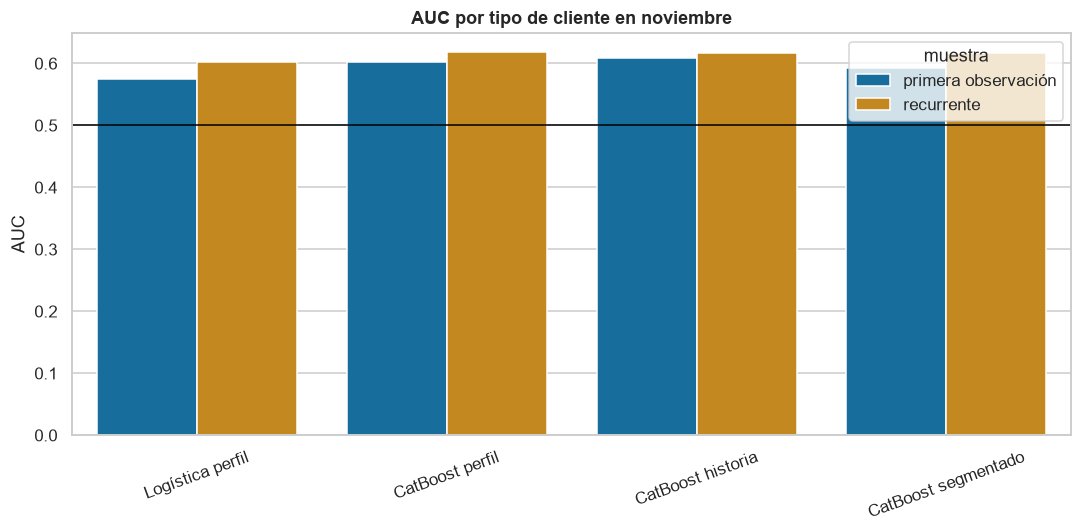

In [11]:
# El test real mezcla nuevas altas y sobrevivientes; se reportan ambos segmentos.
subgrupos = []
for nombre in ["Logística perfil", "CatBoost perfil", "CatBoost historia", "CatBoost segmentado"]:
    p = predicciones_noviembre[nombre]
    for primera, etiqueta in [(1, "primera observación"), (0, "recurrente")]:
        mask = val_temporal["primera_observacion"].eq(primera).to_numpy()
        subgrupos.append(metricas(
            val_temporal.loc[mask, "objetivo"], p[mask], nombre,
            "subgrupo", muestra=etiqueta,
        ))
tabla_subgrupos = pd.DataFrame(subgrupos)
display(tabla_subgrupos[["modelo", "muestra", "n", "tasa_real", "prob_media", "AUC", "Gini", "Brier"]])

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=tabla_subgrupos, x="modelo", y="AUC", hue="muestra", ax=ax)
ax.axhline(.5, color="black", lw=1)
ax.set(title="AUC por tipo de cliente en noviembre", xlabel="", ylabel="AUC")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

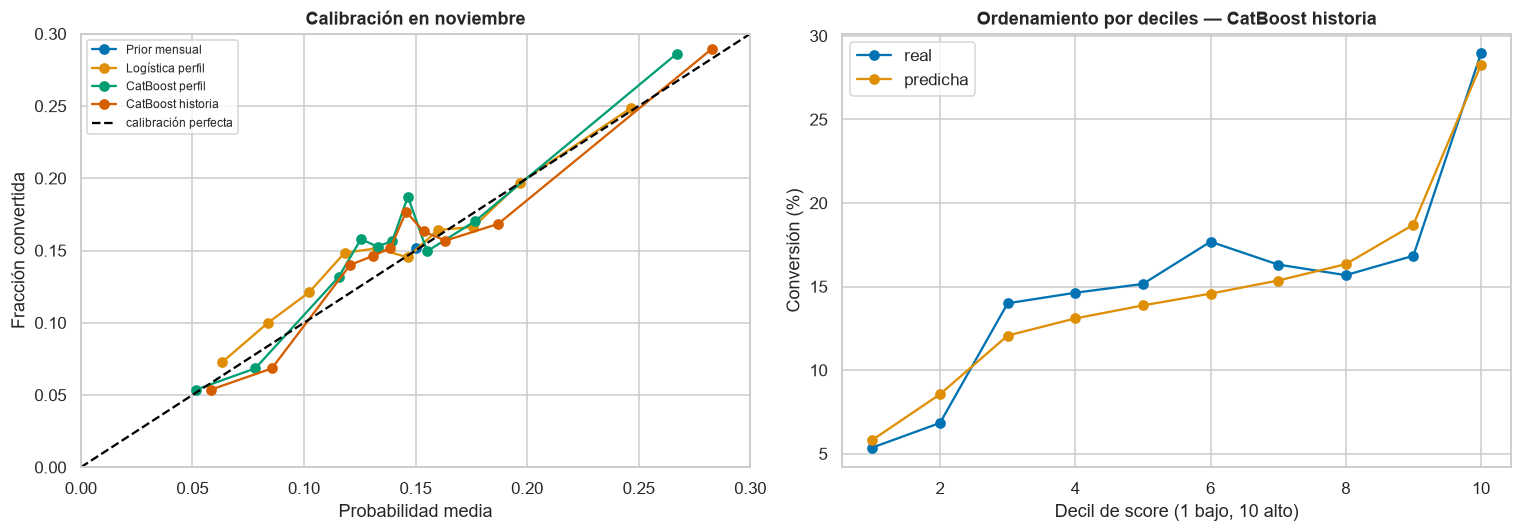

,clientes,tasa_real,prob_media
decil,,,
1,950,0.0537,0.0583
2,950,0.0684,0.0856
3,950,0.1400,0.1207
4,950,0.1463,0.1309
5,950,0.1516,0.1387
6,950,0.1768,0.1458
7,950,0.1632,0.1536
8,950,0.1568,0.1634
9,950,0.1684,0.1870


In [12]:
# Curva de calibración y distribución por deciles del mejor baseline mensual.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
y_val = val_temporal["objetivo"].to_numpy()
for nombre in ["Prior mensual", "Logística perfil", "CatBoost perfil", "CatBoost historia"]:
    p = predicciones_noviembre[nombre]
    frac_pos, media_pred = calibration_curve(y_val, p, n_bins=10, strategy="quantile")
    axes[0].plot(media_pred, frac_pos, marker="o", label=nombre)
axes[0].plot([0, .3], [0, .3], ls="--", color="black", label="calibración perfecta")
axes[0].set(title="Calibración en noviembre", xlabel="Probabilidad media", ylabel="Fracción convertida", xlim=(0, .3), ylim=(0, .3))
axes[0].legend(fontsize=8)

mejor = predicciones_noviembre["CatBoost historia"]
deciles = pd.qcut(mejor, 10, labels=False, duplicates="drop") + 1
lift = pd.DataFrame({"decil": deciles, "objetivo": y_val, "prob": mejor}).groupby("decil").agg(
    clientes=("objetivo", "size"), tasa_real=("objetivo", "mean"), prob_media=("prob", "mean")
)
axes[1].plot(lift.index, lift["tasa_real"] * 100, marker="o", label="real")
axes[1].plot(lift.index, lift["prob_media"] * 100, marker="o", label="predicha")
axes[1].set(title="Ordenamiento por deciles — CatBoost historia", xlabel="Decil de score (1 bajo, 10 alto)", ylabel="Conversión (%)")
axes[1].legend()
plt.tight_layout()
plt.show()
display(lift)

## 8. ¿Qué aprende CatBoost?

,variable,importancia
10,banda_riesgo,35.8715
4,numero_productos,16.2155
6,dias_ultima_transaccion,11.5218
12,activo_movil,5.9238
11,tiene_tarjeta_credito,3.9756
2,ratio_deuda_ingresos,2.6483
25,mes_ordinal,2.0587
21,dias_ultima_interaccion,2.0423
1,ingresos,1.9576
26,interaccion_previa,1.7606


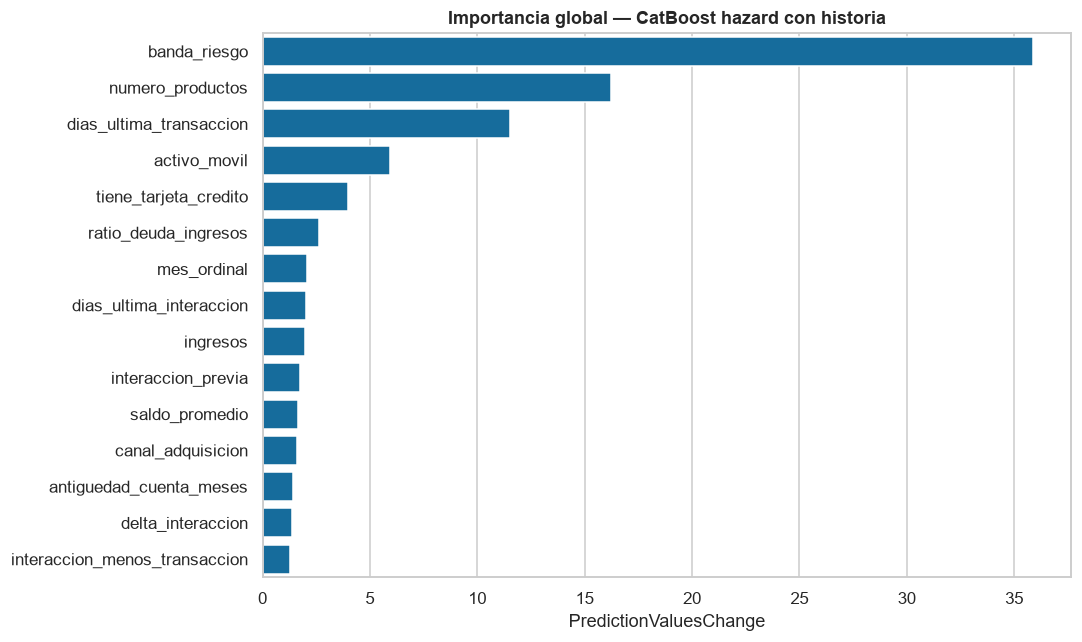

In [13]:
importancia = pd.DataFrame({
    "variable": historia,
    "importancia": cat_historia.get_feature_importance(type="PredictionValuesChange"),
}).sort_values("importancia", ascending=False)
display(importancia.head(15))

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=importancia.head(15), y="variable", x="importancia", color="#0072B2", ax=ax)
ax.set(title="Importancia global — CatBoost hazard con historia", xlabel="PredictionValuesChange", ylabel="")
plt.tight_layout()
plt.show()

Esta importancia mide cuánto usa el modelo cada variable, no causalidad. Conviene contrastarla con el EDA: `banda_riesgo`, productos y recencias deberían dominar; una importancia alta de cohorte/exposición puede ser útil, pero también puede capturar el mecanismo sintético de generación.

## 9. F0 — Split aleatorio como control negativo

In [14]:
# Se limita a ene-oct para comparar con el universo de entrenamiento principal.
iid_train, iid_val = train_test_split(
    dev_temporal, test_size=.12, random_state=SEED, stratify=dev_temporal["objetivo"]
)
overlap = len(set(iid_train["id_cliente"]) & set(iid_val["id_cliente"]))

inicio = time.perf_counter()
cat_iid = crear_catboost()
cat_iid.fit(
    iid_train[perfil], iid_train["objetivo"],
    cat_features=[c for c in perfil if c in categoricas],
    eval_set=(iid_val[perfil], iid_val["objetivo"]),
    early_stopping_rounds=50,
    verbose=False,
)
p_iid = cat_iid.predict_proba(iid_val[perfil])[:, 1]
resultado_iid = metricas(
    iid_val["objetivo"], p_iid, "CatBoost", "F0 i.i.d. inválida",
    muestra="holdout aleatorio", segundos=time.perf_counter() - inicio,
)
display(pd.DataFrame([resultado_iid]))
display(pd.Series({
    "clientes en validación aleatoria": iid_val["id_cliente"].nunique(),
    "también presentes en train aleatorio": overlap,
    "% clientes de validación filtrados": overlap / iid_val["id_cliente"].nunique(),
}, name="valor").to_frame())

,formulación,modelo,muestra,n,tasa_real,prob_media,AUC,Gini,AP,LogLoss,Brier,segundos
0,F0 i.i.d. inválida,CatBoost,holdout aleatorio,12072,0.1503,0.1502,0.6313,0.2626,0.2445,0.4062,0.1231,24.6692


,valor
clientes en validación aleatoria,"8,994.0000"
también presentes en train aleatorio,"8,282.0000"
% clientes de validación filtrados,0.9208


F0 suele producir una AUC mayor, pero no es una mejora de modelo: más del 90% de los clientes de validación también aparecen en entrenamiento y se mezclan meses futuros/pasados. Se reporta para demostrar el sesgo, no como candidato.

## 10. Backtesting temporal: ¿el resultado de noviembre es estable?

,modelo,muestra,n,tasa_real,prob_media,AUC,Gini,LogLoss,Brier,iteraciones
0,Logística historia,202608,10050,0.1442,0.1527,0.6246,0.2493,0.4000,0.1202,NaN
1,CatBoost historia,202608,10050,0.1442,0.1471,0.6313,0.2626,0.3958,0.1191,198.0000
2,Logística historia,202609,9900,0.1407,0.1492,0.6155,0.2309,0.3952,0.1180,NaN
3,CatBoost historia,202609,9900,0.1407,0.1458,0.6240,0.2481,0.3912,0.1170,98.0000
4,Logística historia,202610,10400,0.1565,0.1472,0.6201,0.2403,0.4216,0.1286,NaN
5,CatBoost historia,202610,10400,0.1565,0.1432,0.6370,0.2740,0.4160,0.1271,162.0000
6,Logística historia,202611,9500,0.1515,0.1496,0.6007,0.2015,0.4168,0.1263,NaN
7,CatBoost historia,202611,9500,0.1515,0.1467,0.6190,0.2381,0.4102,0.1247,164.0000


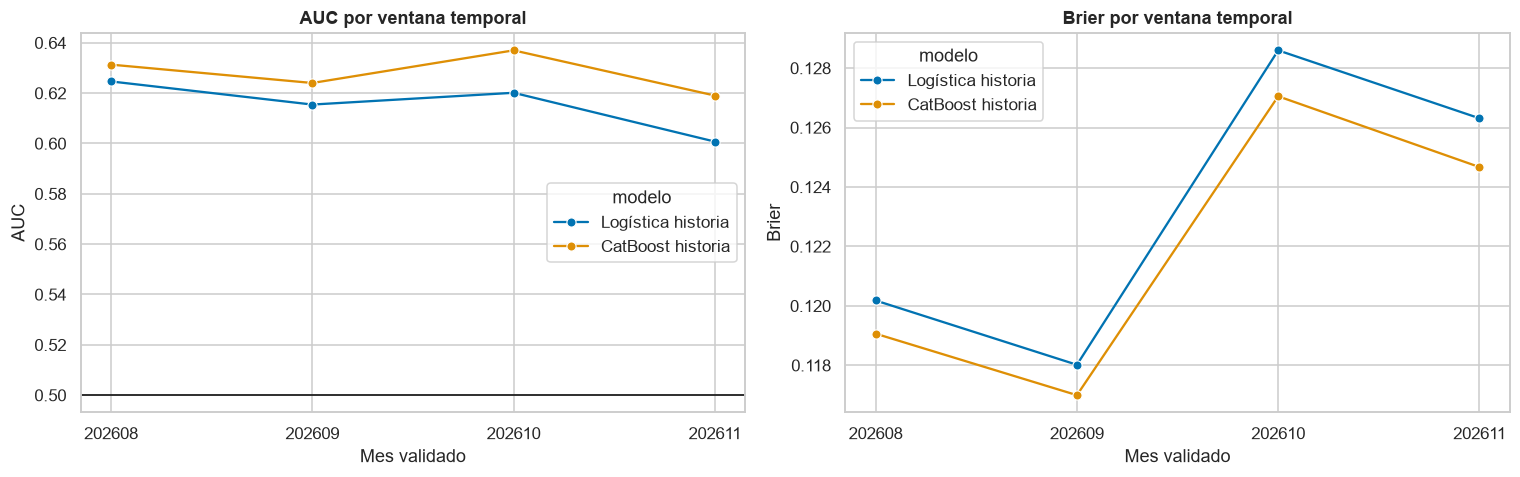

In [15]:
# Ventanas expansivas. Se compara la logística rápida con CatBoost historia.
backtest_rows = []
for mes_val in [202608, 202609, 202610, 202611]:
    dtr = desarrollo.loc[desarrollo["mes"].lt(mes_val)]
    dva = desarrollo.loc[desarrollo["mes"].eq(mes_val)]

    log_bt = crear_logistica(historia)
    log_bt.fit(dtr[historia], dtr["objetivo"])
    p_log = log_bt.predict_proba(dva[historia])[:, 1]
    backtest_rows.append(metricas(
        dva["objetivo"], p_log, "Logística historia", "backtest", muestra=str(mes_val)
    ))

    cat_bt = crear_catboost(iterations=280)
    cat_bt.fit(
        dtr[historia], dtr["objetivo"],
        cat_features=[c for c in historia if c in categoricas],
        eval_set=(dva[historia], dva["objetivo"]),
        early_stopping_rounds=40,
        verbose=False,
    )
    p_cat = cat_bt.predict_proba(dva[historia])[:, 1]
    fila = metricas(dva["objetivo"], p_cat, "CatBoost historia", "backtest", muestra=str(mes_val))
    fila["iteraciones"] = cat_bt.get_best_iteration()
    backtest_rows.append(fila)

backtest = pd.DataFrame(backtest_rows)
display(backtest[["modelo", "muestra", "n", "tasa_real", "prob_media", "AUC", "Gini", "LogLoss", "Brier", "iteraciones"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.lineplot(data=backtest, x="muestra", y="AUC", hue="modelo", marker="o", ax=axes[0])
axes[0].axhline(.5, color="black", lw=1)
axes[0].set(title="AUC por ventana temporal", xlabel="Mes validado", ylabel="AUC")
sns.lineplot(data=backtest, x="muestra", y="Brier", hue="modelo", marker="o", ax=axes[1])
axes[1].set(title="Brier por ventana temporal", xlabel="Mes validado", ylabel="Brier")
plt.tight_layout()
plt.show()

## 11. F4 — Conversión acumulada a tres meses desde el alta

In [16]:
# Una fila por cliente en su entrada. Solo cohortes con tres meses completamente observables.
primera_fila = panel.groupby("id_cliente", as_index=False).first()
mes_evento = (
    train_raw.loc[train_raw["objetivo"].eq(1), ["id_cliente", "mes"]]
    .rename(columns={"mes": "mes_evento"})
)
cohortes = primera_fila.merge(mes_evento, on="id_cliente", how="left")
distancia_evento = indice_mensual(cohortes["mes_evento"].fillna(999999).astype(int)) - indice_mensual(cohortes["mes"])
cohortes["convierte_3m"] = distancia_evento.between(0, 2).astype(int)

# Septiembre puede observarse hasta noviembre. Enero-agosto forman desarrollo.
coh_dev = cohortes.loc[cohortes["mes"].le(202608)].copy()
coh_val = cohortes.loc[cohortes["mes"].eq(202609)].copy()
for col in categoricas:
    coh_dev[col] = coh_dev[col].astype(str)
    coh_val[col] = coh_val[col].astype(str)

resultados_3m = []
p_prior_3m = np.repeat(coh_dev["convierte_3m"].mean(), len(coh_val))
resultados_3m.append(metricas(
    coh_val["convierte_3m"], p_prior_3m, "Prior cohorte", "F4 Conversión 3 meses", muestra="cohorte septiembre"
))

log_3m = crear_logistica(perfil)
log_3m.fit(coh_dev[perfil], coh_dev["convierte_3m"])
p_log_3m = log_3m.predict_proba(coh_val[perfil])[:, 1]
resultados_3m.append(metricas(
    coh_val["convierte_3m"], p_log_3m, "Logística", "F4 Conversión 3 meses", muestra="cohorte septiembre"
))

cat_3m = crear_catboost()
cat_3m.fit(
    coh_dev[perfil], coh_dev["convierte_3m"],
    cat_features=[c for c in perfil if c in categoricas],
    eval_set=(coh_val[perfil], coh_val["convierte_3m"]),
    early_stopping_rounds=50,
    verbose=False,
)
p_cat_3m = cat_3m.predict_proba(coh_val[perfil])[:, 1]
resultados_3m.append(metricas(
    coh_val["convierte_3m"], p_cat_3m, "CatBoost", "F4 Conversión 3 meses", muestra="cohorte septiembre"
))
tabla_3m = pd.DataFrame(resultados_3m).sort_values("AUC", ascending=False)
display(pd.Series({
    "clientes desarrollo": len(coh_dev),
    "clientes validación septiembre": len(coh_val),
    "tasa 3m desarrollo": coh_dev["convierte_3m"].mean(),
    "tasa 3m septiembre": coh_val["convierte_3m"].mean(),
}, name="valor").to_frame())
display(tabla_3m)

,valor
clientes desarrollo,"20,708.0000"
clientes validación septiembre,"1,299.0000"
tasa 3m desarrollo,0.3969
tasa 3m septiembre,0.4249


,formulación,modelo,muestra,n,tasa_real,prob_media,AUC,Gini,AP,LogLoss,Brier,segundos
2,F4 Conversión 3 meses,CatBoost,cohorte septiembre,1299,0.4249,0.3946,0.6677,0.3355,0.6228,0.6308,0.2207,NaN
1,F4 Conversión 3 meses,Logística,cohorte septiembre,1299,0.4249,0.3932,0.6537,0.3073,0.5959,0.6466,0.2274,NaN
0,F4 Conversión 3 meses,Prior cohorte,cohorte septiembre,1299,0.4249,0.3969,0.5000,0.0000,0.4249,0.6835,0.2452,NaN


F4 puede mostrar AUC mayor porque acumula tres oportunidades de conversión y solo evalúa altas nuevas. **No debe concluirse que supera a F1/F2:** cambia población, etiqueta, prevalencia y horizonte. Es apropiada para decidir a quién contactar al adquirir un cliente; no entrega directamente la probabilidad de conversión en diciembre para sobrevivientes.

## 12. Selección del baseline y entrenamiento final

In [17]:
# Selección por formulación válida + AUC temporal, usando historia por coherencia del problema.
mejores_iters = [
    int(x) for x in backtest.loc[backtest["modelo"].eq("CatBoost historia"), "iteraciones"].dropna()
    if x >= 0
]
iter_final = max(80, int(np.median(mejores_iters)) + 1)

cat_final = crear_catboost(iterations=iter_final)
cat_final.fit(
    desarrollo[historia], desarrollo["objetivo"],
    cat_features=[c for c in historia if c in categoricas],
    verbose=False,
)
pred_test = cat_final.predict_proba(test_modelo[historia])[:, 1]

submission = sample_submission.copy()
assert submission["id_cliente"].equals(test_raw["id_cliente"])
submission["prediccion"] = pred_test
assert submission["prediccion"].between(0, 1).all()
submission.to_csv("submission_baseline_catboost_historia.csv", index=False)

display(pd.Series({
    "iteraciones finales": iter_final,
    "filas submission": len(submission),
    "probabilidad mínima": pred_test.min(),
    "probabilidad media": pred_test.mean(),
    "probabilidad máxima": pred_test.max(),
    "archivo": "submission_baseline_catboost_historia.csv",
}, name="valor").to_frame())
display(submission.head())

,valor
iteraciones finales,164
filas submission,9900
probabilidad mínima,0.0336
probabilidad media,0.1502
probabilidad máxima,0.4384
archivo,submission_baseline_catboost_historia.csv


,id_cliente,prediccion
0,2,0.1457
1,3,0.0594
2,7,0.1461
3,10,0.0606
4,11,0.1568


## 13. Conclusiones

In [18]:
mejor_mensual = tabla_mensual.iloc[0]
auc_iid = resultado_iid["AUC"]
auc_temporal = tabla_mensual.loc[
    (tabla_mensual["formulación"].eq("F2 Hazard + historia")) &
    (tabla_mensual["modelo"].eq("CatBoost")), "AUC"
].iloc[0]
mejor_3m = tabla_3m.iloc[0]
tasa_nuevos = val_temporal.loc[val_temporal["primera_observacion"].eq(1), "objetivo"].mean()
tasa_rec = val_temporal.loc[val_temporal["primera_observacion"].eq(0), "objetivo"].mean()

display(Markdown(f'''
1. **Baseline recomendado:** F2, hazard mensual con historia + CatBoost. En noviembre obtiene AUC **{auc_temporal:.4f}** y Gini **{2*auc_temporal-1:.4f}**. La ventaja frente al CatBoost de perfil es pequeña; se elige por coherencia temporal y mejor calibración, no por una diferencia estadísticamente contundente.
2. **La complejidad lineal pierde señal:** la logística es un baseline honesto, pero no captura tan bien umbrales e interacciones como CatBoost.
3. **Segmentar no ayudó:** el modelo separado para altas tiene poca muestra y peor ranking. Un único modelo con `primera_observacion` comparte fuerza estadística y funciona mejor.
4. **El split aleatorio engaña:** AUC **{auc_iid:.4f}** frente a **{auc_temporal:.4f}** fuera de tiempo, con la gran mayoría de identidades repetidas entre train y validación.
5. **Hay heterogeneidad de población:** en noviembre la tasa fue **{tasa_nuevos:.2%}** para primeras observaciones y **{tasa_rec:.2%}** para recurrentes; deben monitorearse por separado aunque se use un solo modelo.
6. **F4 responde otra decisión:** el mejor baseline a tres meses alcanza AUC **{mejor_3m['AUC']:.4f}**, pero no es comparable con el hazard mensual y no sustituye al modelo de competencia.
7. **Siguiente mejora con mayor retorno:** optimización moderada de CatBoost con backtesting, calibración out-of-fold temporal y ensamblado con logística. Evitar ingeniería de deltas sobre las 21 variables congeladas y no usar `id_cliente` directamente.
'''))


1. **Baseline recomendado:** F2, hazard mensual con historia + CatBoost. En noviembre obtiene AUC **0.6190** y Gini **0.2381**. La ventaja frente al CatBoost de perfil es pequeña; se elige por coherencia temporal y mejor calibración, no por una diferencia estadísticamente contundente.
2. **La complejidad lineal pierde señal:** la logística es un baseline honesto, pero no captura tan bien umbrales e interacciones como CatBoost.
3. **Segmentar no ayudó:** el modelo separado para altas tiene poca muestra y peor ranking. Un único modelo con `primera_observacion` comparte fuerza estadística y funciona mejor.
4. **El split aleatorio engaña:** AUC **0.6313** frente a **0.6190** fuera de tiempo, con la gran mayoría de identidades repetidas entre train y validación.
5. **Hay heterogeneidad de población:** en noviembre la tasa fue **19.64%** para primeras observaciones y **14.77%** para recurrentes; deben monitorearse por separado aunque se use un solo modelo.
6. **F4 responde otra decisión:** el mejor baseline a tres meses alcanza AUC **0.6677**, pero no es comparable con el hazard mensual y no sustituye al modelo de competencia.
7. **Siguiente mejora con mayor retorno:** optimización moderada de CatBoost con backtesting, calibración out-of-fold temporal y ensamblado con logística. Evitar ingeniería de deltas sobre las 21 variables congeladas y no usar `id_cliente` directamente.
